# Project III

In [2]:
%load_ext autoreload
%autoreload 2
import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import chi2
from scipy.stats import norm
from scipy import optimize

import w8_estimation as est 
import w8_LinearModel as lm
import w8_probit as probit
import w8_logit as logit

In [3]:
dat = pd.read_csv('ppcs_cc.csv')

# Paste this into code
#ll = (y)*norm.logcdf(z) + (1-y)*norm.logcdf(-z)

In [4]:
dat.sample(5)
dat['const'] = 1
dat['age20_30']=((dat['sage'] >= 20) & (dat['sage'] < 30)).astype(int)
dat['under50']=((dat['sage'] < 50)).astype(int)
dat['age_sq'] = dat['sage']**2
dat['age_divided_by_10'] = dat['sage']/10

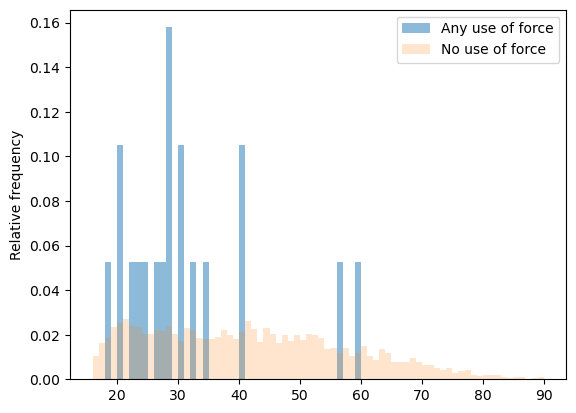

In [5]:
force_ages = dat.loc[dat["anyuseofforce_coded"] == 1, "sage"]
no_force_ages = dat.loc[dat["anyuseofforce_coded"] == 0, "sage"]
bins = np.histogram_bin_edges(dat["sage"], bins=74)

fig, ax = plt.subplots()
ax.hist(force_ages, bins=bins, weights=np.ones(len(force_ages)) / len(force_ages), alpha=0.5, label="Any use of force")
ax.hist(no_force_ages, bins=bins, weights=np.ones(len(no_force_ages)) / len(no_force_ages), alpha=0.2, label="No use of force")
ax.set_ylabel("Relative frequency")
ax.legend()

In [ ]:
# Quasi-complete seperation issues:
pd.crosstab(dat['anyuseofforce_coded'], dat['omajother'], margins=True)
pd.crosstab(dat['anyuseofforce_coded'], dat['omajblack'], margins=True)
pd.crosstab(dat['anyuseofforce_coded'], dat['omajhisp'], margins=True)


sbehavior,0,1,All
anyuseofforce_coded,,,
0,3543,237,3780
1,9,10,19
All,3552,247,3799


In [7]:
df = dat[["anyuseofforce_coded", "sage", "sblack", "smale", "age20_30", "const", "under50", "age_sq", "age_divided_by_10"]]
y = df.anyuseofforce_coded.values
x = df[["sage"]].values
N = y.shape[0]
ols = lm.estimate(y=y, x=x)
print(ols)

theta0 = np.array([0])  # Initial guess for the parameters
#probit = est.estimate(probit.q, theta0, y=y, x=x, method='BFGS')

theta0 = theta0.flatten()
Q = lambda theta: np.mean(probit.q(theta, y, x))
result = optimize.minimize(Q, theta0, method="BFGS", jac='numeric')
print(result)


f_q = lambda theta : probit.q(theta,y,x) # as q(), but only a function of theta, whereas q also takes y,x as inputs
s = est.centered_grad(f_q, result.x)

print(np.sqrt(np.diag(1/N * s.T@s)))

{'b_hat': array([7.92740825e-05]), 'se': array([2.60049688e-05]), 't': array([3.0484206]), 'cov': array([[6.76258402e-10]]), 'sigma2': np.float64(0.004990422501776454), 'R2': np.float64(-0.0025733791419766394)}
  message: Optimization terminated successfully.
  success: True
   status: 0
      fun: 0.03934922664218835
        x: [-8.460e-02]
      nit: 9
      jac: [ 8.149e-08]
 hess_inv: [[ 3.567e-02]]
     nfev: 30
     njev: 15
[8.75034606]


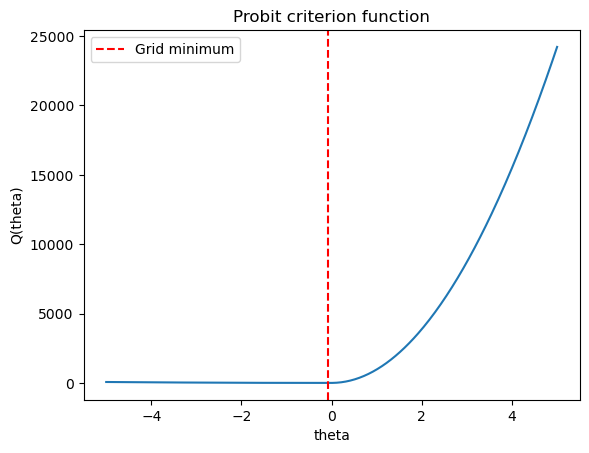

In [8]:
single_x = df[["sage"]].values
Q = lambda theta: np.mean(probit.q(theta, y, single_x))

theta_values = np.linspace(-5, 5, 400)
q_values = [Q(np.array([theta])) for theta in theta_values]

fig, ax = plt.subplots()
ax.plot(theta_values, q_values)
ax.axvline(theta_values[np.argmin(q_values)], color="red", linestyle="--", label="Grid minimum")
ax.set_xlabel("theta")
ax.set_ylabel("Q(theta)")
ax.set_title("Probit criterion function")
ax.legend()